# 03 - Modelamiento 02: Random Forest Regressor y comparación

**Objetivo:** entrenar un segundo modelo, Random Forest, evaluarlo con las mismas métricas que la regresión lineal (MAE, RMSE y R²) y compararlos.

Random Forest combina muchos árboles de decisión. Puede capturar relaciones que no son lineales, como el cambio de comportamiento del descuento que se vio en la exploración.

In [ ]:
import sys
sys.path.append("../..")

import json
import pandas as pd
import matplotlib.pyplot as plt

from src.carga_datos import cargar_csv
from src.transformacion import separar_x_y, separar_train_test, codificar_categoricas
from src.entrenamiento import entrenar_regresion_lineal, entrenar_random_forest, guardar_modelo
from src.evaluacion import calcular_metricas, comparar_modelos, graficar_real_vs_predicho, graficar_residuos

## 1. Carga de train y test

In [ ]:
train = cargar_csv("../../data/train/train.csv")
test = cargar_csv("../../data/test/test.csv")

X_train, y_train = separar_x_y(train, "Profit")
X_test, y_test = separar_x_y(test, "Profit")
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (7959, 39) | X_test: (2035, 39)


## 2. Entrenamiento con train

Parámetros del modelo (definidos en `src/entrenamiento.py`):

- `n_estimators=100`: 100 árboles.
- `max_depth=12`: se limita la profundidad para que los árboles no memoricen los datos de entrenamiento.
- `min_samples_leaf=5`: cada hoja debe tener al menos 5 registros, para evitar reglas basadas en casos aislados.
- `random_state=42`.

No se hizo búsqueda de hiperparámetros para mantener el proyecto sencillo; se deja como mejora futura.

In [ ]:
modelo_rf = entrenar_random_forest(X_train, y_train)
print("Random Forest entrenado")

Random Forest entrenado


## 3. Evaluación con test

In [ ]:
y_predicho_rf = modelo_rf.predict(X_test)
metricas_rf = calcular_metricas(y_test, y_predicho_rf)

for nombre, valor in metricas_rf.items():
    print(f"{nombre}: {valor:.3f}")

MAE: 21.115
RMSE: 97.203
R2: 0.825


## 4. Gráficos

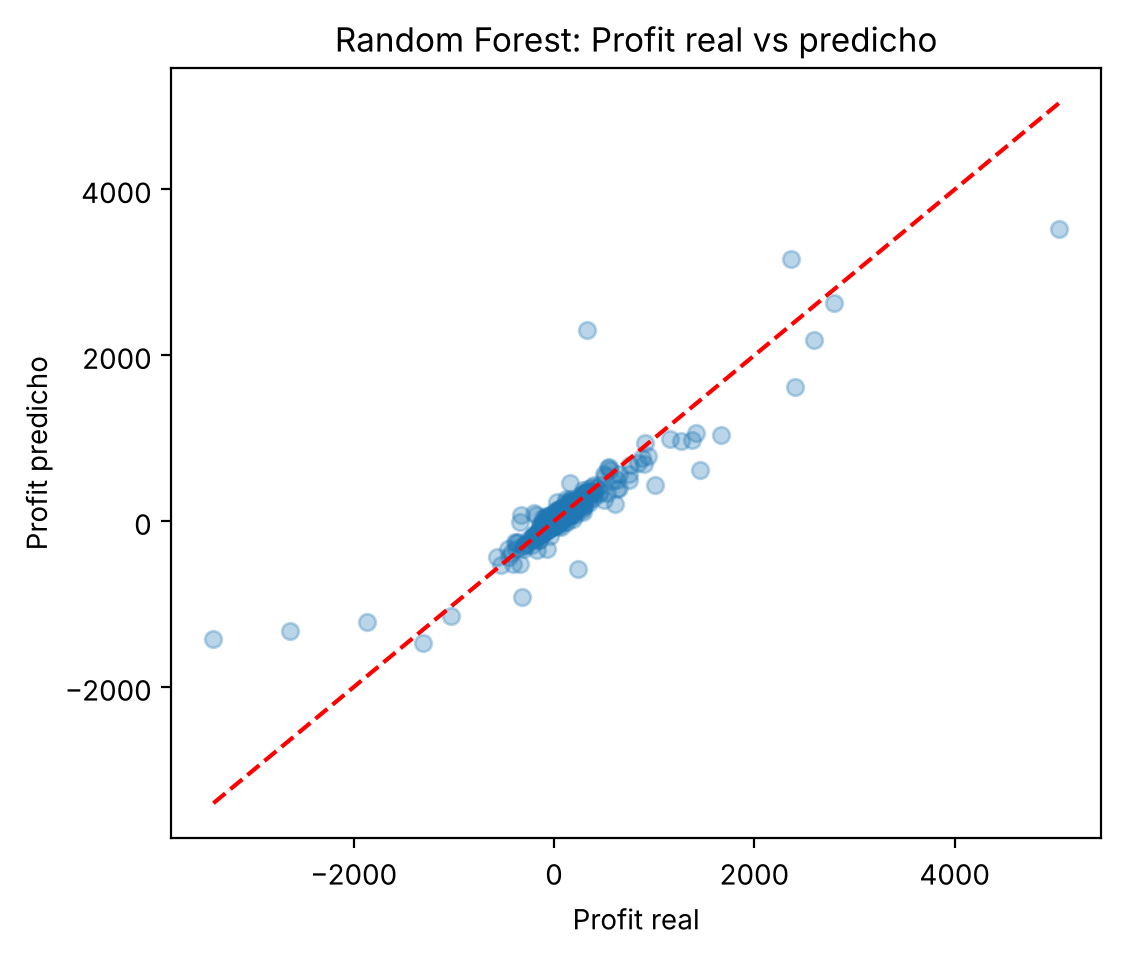

In [ ]:
graficar_real_vs_predicho(y_test, y_predicho_rf, "Random Forest: Profit real vs predicho")

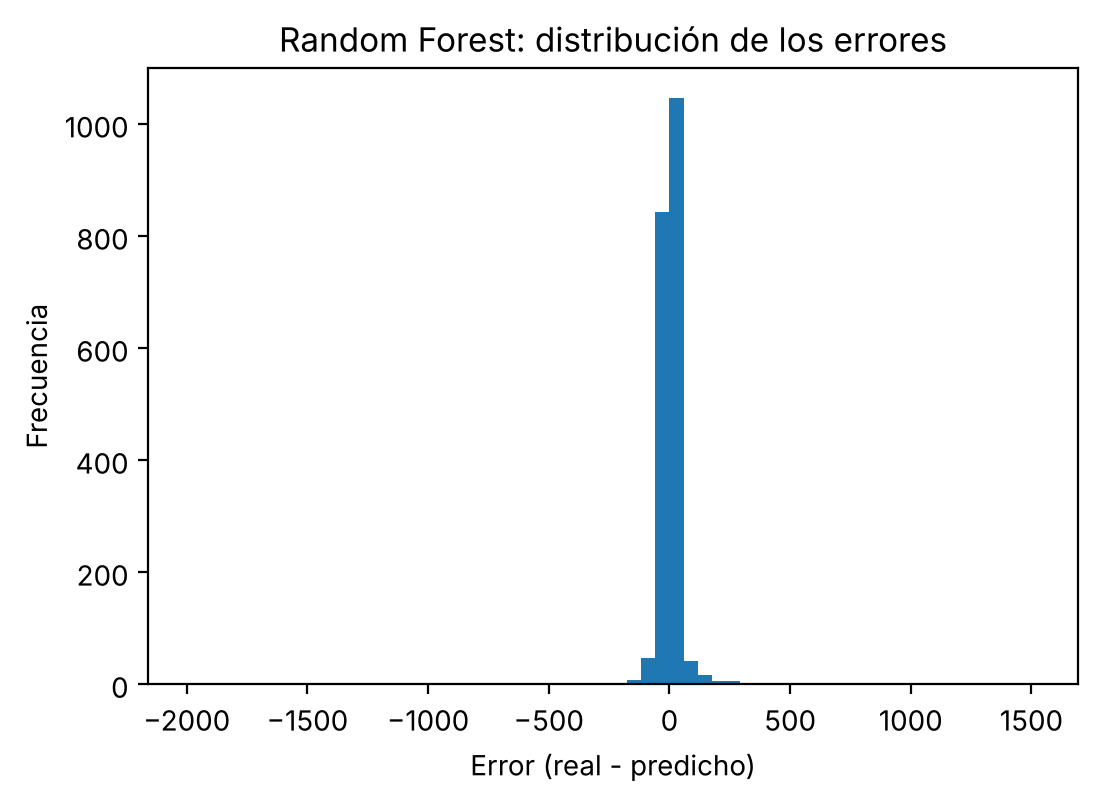

In [ ]:
graficar_residuos(y_test, y_predicho_rf, "Random Forest: distribución de los errores")

## 5. Importancia de las variables

In [ ]:
importancias = pd.Series(modelo_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importancias.head(10).round(3)

Sales                    0.343
Sales_Log                0.337
Discount                 0.213
Sub-Category_Binders     0.017
Sub-Category_Machines    0.017
Sub-Category_Copiers     0.008
Quantity                 0.008
Category_Furniture       0.007
Category_Technology      0.006
Anio_Pedido              0.005
dtype: float64

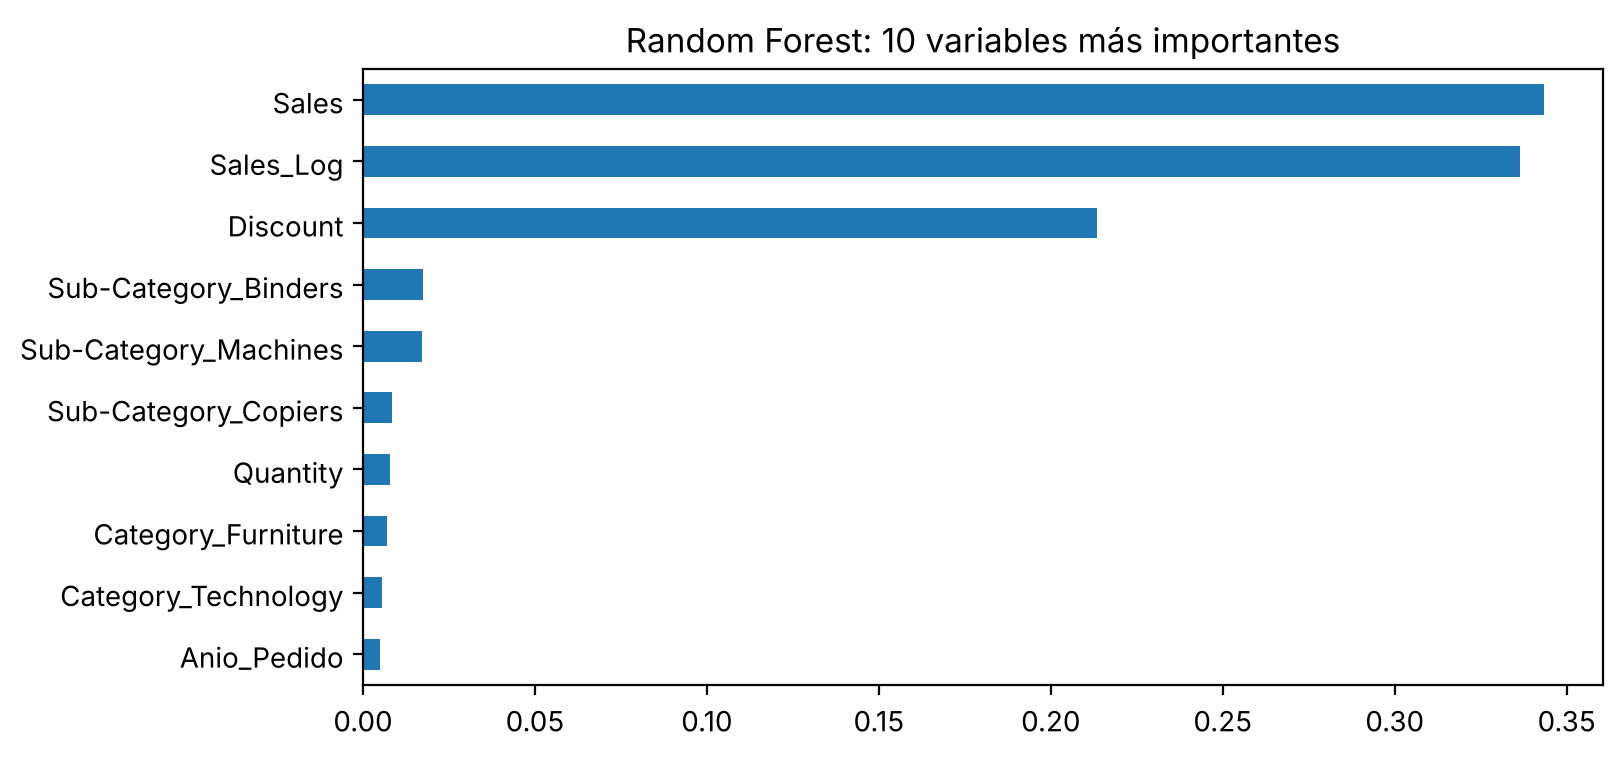

In [ ]:
importancias.head(10).sort_values().plot(kind="barh", figsize=(8, 4))
plt.title("Random Forest: 10 variables más importantes")
plt.show()

## 6. Comparación de los dos modelos
Para que la comparación sea justa, la regresión lineal se vuelve a entrenar y evaluar aquí con los mismos datos.

In [ ]:
modelo_lineal = entrenar_regresion_lineal(X_train, y_train)
metricas_lineal = calcular_metricas(y_test, modelo_lineal.predict(X_test))

tabla = comparar_modelos({
    "Regresión Lineal": metricas_lineal,
    "Random Forest": metricas_rf,
})
tabla

,MAE,RMSE,R2
Regresión Lineal,61.924,171.369,0.455
Random Forest,21.115,97.203,0.825


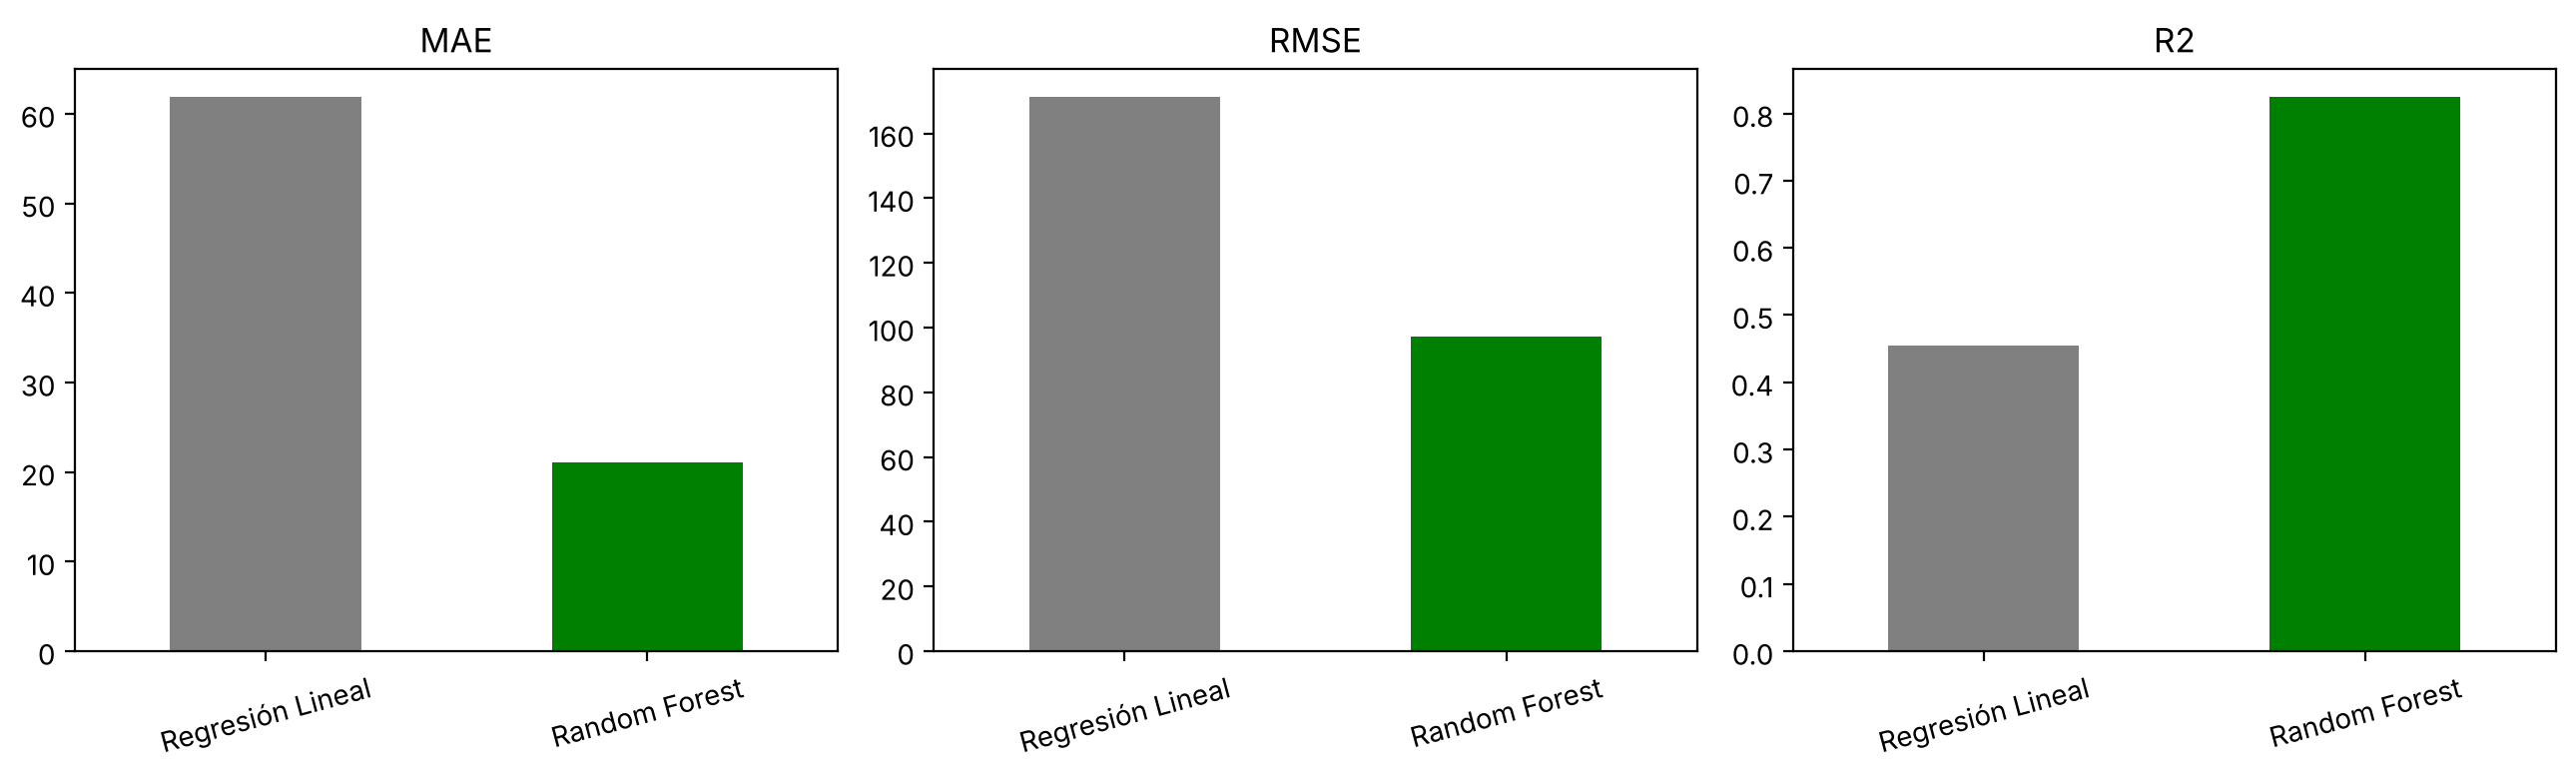

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4))
for eje, metrica in zip(ejes, ["MAE", "RMSE", "R2"]):
    tabla[metrica].plot(kind="bar", ax=eje, color=["gray", "green"])
    eje.set_title(metrica)
    eje.set_xticklabels(tabla.index, rotation=15)
plt.tight_layout()
plt.show()

## 7. Verificación: ¿qué tan estables son los resultados?

Dos revisiones antes de sacar conclusiones. Primero, comparo las métricas en train y en test para ver si hay sobreajuste. Segundo, repito el proceso con otras separaciones train/test (semillas 1, 2 y 3, solo para esta verificación) para ver si el resultado depende de cómo cayeron los registros extremos.

In [ ]:
for nombre, modelo in [("Regresión Lineal", modelo_lineal), ("Random Forest", modelo_rf)]:
    en_train = calcular_metricas(y_train, modelo.predict(X_train))
    en_test = calcular_metricas(y_test, modelo.predict(X_test))
    print(f"{nombre}: R2 train = {en_train['R2']:.3f} | R2 test = {en_test['R2']:.3f}")

Regresión Lineal: R2 train = 0.311 | R2 test = 0.455
Random Forest: R2 train = 0.705 | R2 test = 0.825


In [ ]:
df_limpio = cargar_csv("../../data/modificado/superstore_limpio.csv")
columnas_categoricas = ["Ship Mode", "Segment", "Region", "Category", "Sub-Category"]

filas = []
for semilla in [1, 2, 3]:
    tr, te = separar_train_test(df_limpio, semilla=semilla)
    tr = tr.drop(columns=["Order ID"])
    te = te.drop(columns=["Order ID"])
    tr, te = codificar_categoricas(tr, te, columnas_categoricas)
    Xa, ya = separar_x_y(tr, "Profit")
    Xb, yb = separar_x_y(te, "Profit")
    r2_lineal = calcular_metricas(yb, entrenar_regresion_lineal(Xa, ya).predict(Xb))["R2"]
    r2_rf = calcular_metricas(yb, entrenar_random_forest(Xa, ya).predict(Xb))["R2"]
    filas.append({"Semilla": semilla, "R2 Lineal": round(r2_lineal, 3), "R2 Random Forest": round(r2_rf, 3)})

pd.DataFrame(filas)

,Semilla,R2 Lineal,R2 Random Forest
0,1,0.482,0.809
1,2,0.357,0.643
2,3,0.154,0.499


## 8. Guardado del modelo para el despliegue
Se guarda el modelo final y la lista de columnas que espera, para usarlos después en la aplicación de Streamlit.

In [ ]:
guardar_modelo(modelo_rf, "../../despliegue/modelo/modelo_random_forest.joblib")

with open("../../despliegue/modelo/columnas_modelo.json", "w", encoding="utf-8") as archivo:
    json.dump(list(X_train.columns), archivo, ensure_ascii=False, indent=2)
print("Columnas guardadas:", X_train.shape[1])

Modelo guardado en ../../despliegue/modelo/modelo_random_forest.joblib
Columnas guardadas: 39
